### 2장 6강: 메타데이터 스키마 설계, 저장

**학습 목표**

- 검색 목적에 부합하는 메타데이터 스키마의 구조를 체계적으로 설계할 수 있다.
- LangChain의 Document 객체와 PGVector를 활용해 본문과 메타데이터를 데이터베이스에 동시 저장할 수 있다.
- 메타데이터 조건을 적용해 유사도 검색을 수행하고 LLM 모델과 연결하여 근거 기반 응답을 생성할 수 있다.

In [1]:
import os
from dotenv import load_dotenv
from langchain_openai import OpenAIEmbeddings
# PostgreSQL pgvector 연동 모듈을 불러옵니다.
from langchain_postgres.vectorstores import PGVector

load_dotenv()

embeddings_model = OpenAIEmbeddings(
    model="text-embedding-3-small"
)

# 환경 변수에서 데이터베이스 접속 문자열을 읽어옵니다.
connection_url = os.getenv("DATABASE_URL")

# PGVector 저장소 객체를 생성하고 연결합니다.
vector_store = PGVector(
    embeddings=embeddings_model,     # 임베딩 모델 인스턴스 지정
    collection_name="university_rules", # 데이터를 보관할 컬렉션 테이블 이름
    connection=connection_url,  # 데이터베이스 접속 URL
    use_jsonb=True # 메타데이터를 PostgreSQL JSONB 형태로 저장
)

print("PostgreSQL + pgvector 연결 및 초기화 완료")

PostgreSQL + pgvector 연결 및 초기화 완료


In [2]:
from langchain_core.documents import Document

# 설계한 메타데이터 스키마를 적용한 규정 문서 리스트를 생성합니다.
documents_to_insert = [
    # 1번 문서: 2026학년도 도서관 대출 규정
    Document(
        page_content="[도서관 규정] 학부생은 최대 5권까지 14일간 도서 대출이 가능합니다.",
        metadata={
            "source": "library_guide_2026.pdf",
            "category": "library",
            "year": 2026
        }
    ),
    # 2번 문서: 2027학년도 개정 도서관 대출 규정
    Document(
        page_content="[개정 도서관 규정] 학부생은 최대 7권까지 21일간 도서 대출이 가능합니다.",
        metadata={
            "source": "library_guide_2027.pdf",
            "category": "library",
            "year": 2027
        }
    ),
    # 3번 문서: 2027학년도 장학금 규정
    Document(
        page_content="[장학금 규정] 직전 학기 평점 3.5 이상인 학생은 성적 우수 장학금 대상자입니다.",
        metadata={
            "source": "scholarship_2027.pdf",
            "category": "scholarship",
            "year": 2027
        }
    )
]


# 각 문서에 일대일로 매핑될 고유 식별자(ID)를 지정합니다.
document_ids = ["doc_lib_2026", "doc_lib_2027", "doc_sch_2027"]

saved_ids = vector_store.add_documents(
    documents=documents_to_insert,
    ids=document_ids
)

# 저장 완료 결과를 화면에 출력합니다.
print(f"DB에 적재된 문서 총 개수: {len(saved_ids)}개")
print(f"저장된 문서 고유 ID 목록: {saved_ids}")

DB에 적재된 문서 총 개수: 3개
저장된 문서 고유 ID 목록: ['doc_lib_2026', 'doc_lib_2027', 'doc_sch_2027']


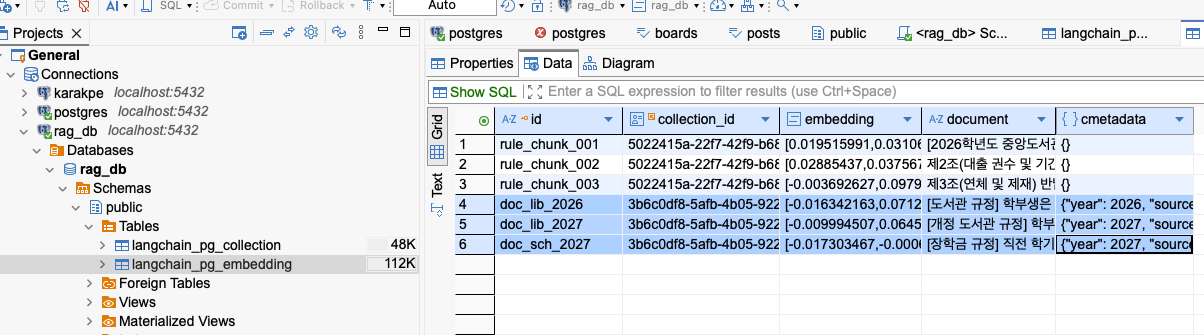

- json 문자열로 메타데이터 추가됨 확인

메타데이터 필터 검색 후 LLM 모델로 답변하기 

In [4]:
# 2027년도 규정만 탐색하도록 메타데이터 필터 조건을 설정합니다.
metadata_filter = {
    "year": 2027,
    "category": "library"
}

user_question = "최대 대출 일수를 알려주람쥐."

# 필터 조건과 함께 벡터 유사도 검색 실행
search_results = vector_store.similarity_search(
    query=user_question,
    k=1,
    filter=metadata_filter
)
print(f"결과: {search_results}")

search_docs = search_results[0]
print(f"검색 본문: {search_docs.page_content}")
print(f"메타데이터: {search_docs.metadata}")

결과: [Document(id='doc_lib_2027', metadata={'year': 2027, 'source': 'library_guide_2027.pdf', 'category': 'library'}, page_content='[개정 도서관 규정] 학부생은 최대 7권까지 21일간 도서 대출이 가능합니다.')]
검색 본문: [개정 도서관 규정] 학부생은 최대 7권까지 21일간 도서 대출이 가능합니다.
메타데이터: {'year': 2027, 'source': 'library_guide_2027.pdf', 'category': 'library'}
